Credit Risk Prediction Classifier

In [72]:
# Import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [73]:
# Load data
df = pd.read_csv('german_credit_data_train.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 86.1 KB


In [74]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [75]:
# Data preprocessing

df.drop(columns=['Unnamed: 0'], inplace=True)
df.head()


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [78]:
# Check each column for null values

df.isnull().any()

# Impute the missing values

df = df.fillna({'Saving accounts' : 'unknown', 'Checking account' : 'unknown'})

df.info()

# Check if there any null present

df.isnull().sum()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   1000 non-null   str  
 5   Checking account  1000 non-null   str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
 9   Risk              1000 non-null   str  
dtypes: int64(4), str(6)
memory usage: 78.3 KB


Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64

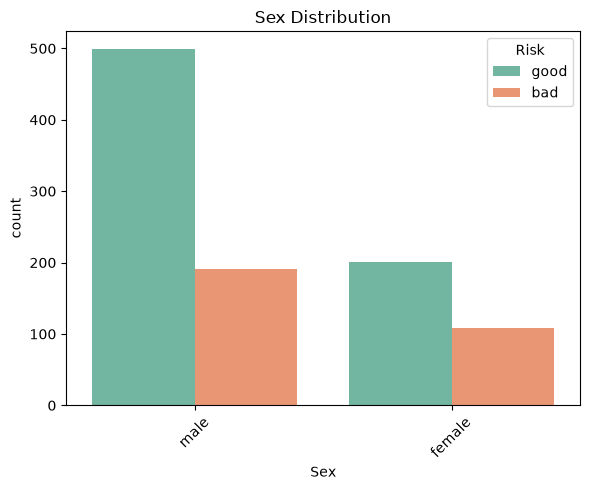

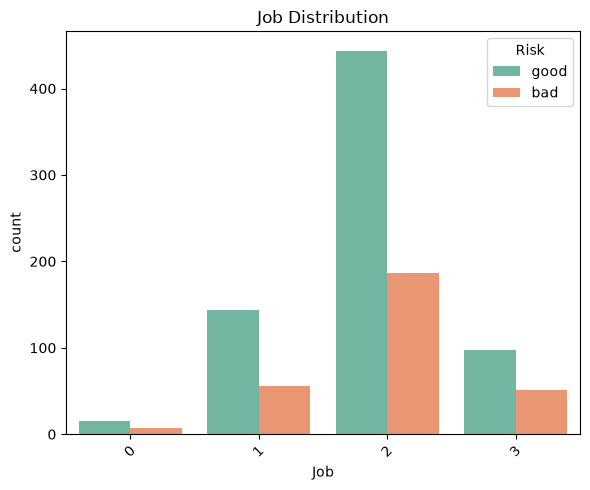

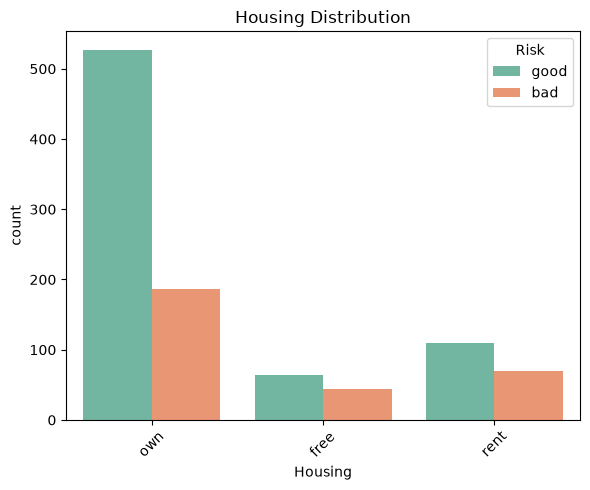

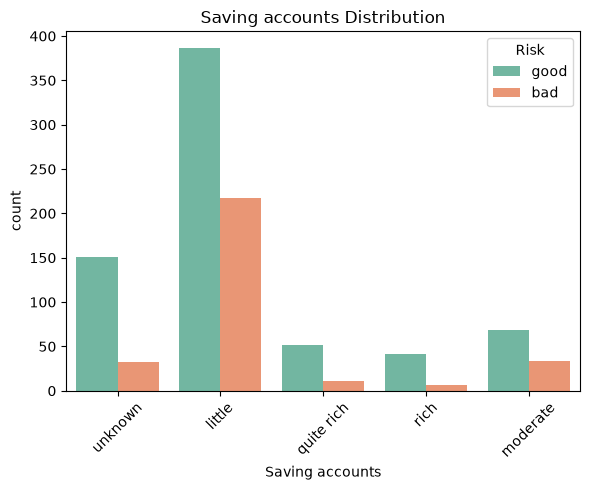

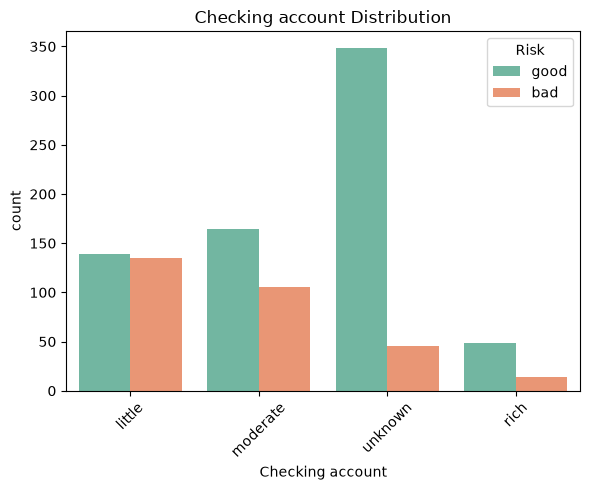

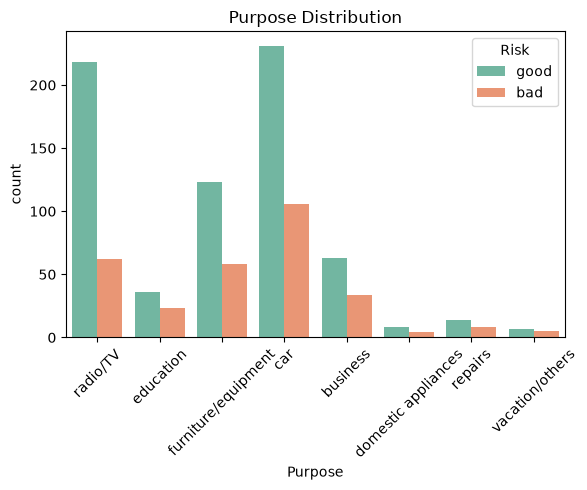

In [80]:
# Visualize Distributions 

# Countplots for Categorical values

cat_cols = ['Sex','Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

for col in cat_cols:
    plt.figure(figsize=(6,5))
    sns.countplot(data=df, x=col, hue='Risk', palette='Set2', legend='auto')
    plt.title(f"{col} Distribution")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


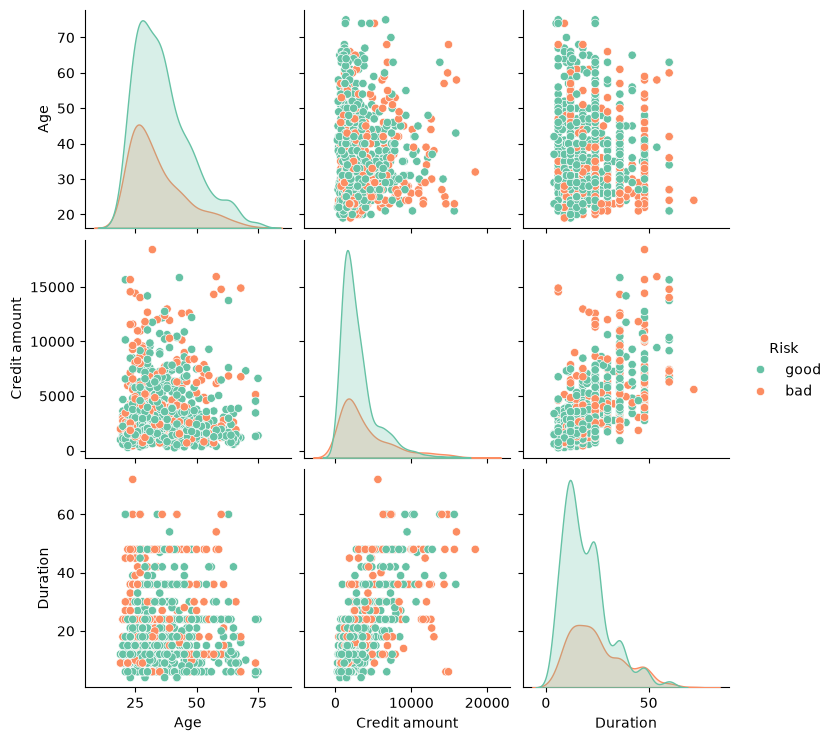

In [83]:
# Pairplots for Numerical values

num_cols = ["Age", "Credit amount", "Duration","Risk"]

num_data_df = df.loc[:, num_cols]
sns.pairplot(num_data_df, hue='Risk', palette='Set2')
plt.show()


In [86]:
# Apply one hot encoding to categorical values

data = df.copy()
data = pd.get_dummies(data,columns=cat_cols,dtype=int)
data.head()

,Age,Credit amount,Duration,Risk,Sex_female,Sex_male,Job_0,Job_1,Job_2,Job_3,...,Checking account_rich,Checking account_unknown,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,67,1169,6,good,0,1,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
1,22,5951,48,bad,1,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
2,49,2096,12,good,0,1,0,1,0,0,...,0,1,0,0,0,1,0,0,0,0
3,45,7882,42,good,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
4,53,4870,24,bad,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0


In [87]:
data.columns

Index(['Age', 'Credit amount', 'Duration', 'Risk', 'Sex_female', 'Sex_male',
       'Job_0', 'Job_1', 'Job_2', 'Job_3', 'Housing_free', 'Housing_own',
       'Housing_rent', 'Saving accounts_little', 'Saving accounts_moderate',
       'Saving accounts_quite rich', 'Saving accounts_rich',
       'Saving accounts_unknown', 'Checking account_little',
       'Checking account_moderate', 'Checking account_rich',
       'Checking account_unknown', 'Purpose_business', 'Purpose_car',
       'Purpose_domestic appliances', 'Purpose_education',
       'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_repairs',
       'Purpose_vacation/others'],
      dtype='str')

In [92]:
# Prepare data for training

X = data.drop(columns=['Risk'])
Y = data['Risk'].map({'Good':1, 'Bad':0})

#X.head()
#Y.head()



0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: Risk, dtype: float64